<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/market-signals/02_regimes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Calm and turbulent regimes: hidden Markov model vs Gaussian mixture

Two-state Gaussian hidden Markov model on daily S&P 500 returns, fitted by EM (forward-backward written in `signals.py`), against a Gaussian mixture on 21-day return and volatility. Then the real-time version: parameters fitted on 2000-2012, filtered probabilities only, used out of sample 2013-2026. Checks: the VIX, Student-t and 3-state models, six other assets, weekly returns. Takes ~7 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/market-signals
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from signals import *
plt.style.use("quant.mplstyle")

spx = load_close("../black-scholes-sp500/data/sp500.csv")
r = np.log(spx).diff().dropna()          # daily log returns
print(len(r), r.index[0].date(), "->", r.index[-1].date())

6761 2000-01-04 -> 2026-11-19


In [3]:
from scipy import stats as st
x = 100 * r                              # in percent
h = hmm2_fit(x.values)
print("mean %/day:", h["mu"].round(3), " vol %/day:", h["sd"].round(2))
print("transition matrix:\n", h["P"].round(4))
print("expected duration (days):", (1 / (1 - np.diag(h["P"]))).round(0))
ll1 = st.norm.logpdf(x, x.mean(), x.std()).sum()
print(f"log-likelihood 2 states {h['loglik']:.0f}, 1 state {ll1:.0f}, likelihood ratio {2 * (h['loglik'] - ll1):.0f} for 4 extra parameters")
# calm state: vol 0.70%/day (11%/yr), +0.08%/day. turbulent: 1.94%/day (31%/yr), -0.11%/day
# both states are persistent: 85 days on average in calm, 35 in turbulent
# likelihood ratio 2,752: two states fit far better than one normal (the usual chi-square does not apply here
# because the null sits on the edge of the parameter space, but the gap is huge)

mean %/day: [ 0.079 -0.11 ]  vol %/day: [0.7  1.94]
transition matrix:
 [[0.9883 0.0117]
 [0.0282 0.9718]]
expected duration (days): [85. 35.]
log-likelihood 2 states -9518, 1 state -10894, likelihood ratio 2752 for 4 extra parameters


In [4]:
from sklearn.mixture import GaussianMixture
hmm = pd.Series(h["smoothed"][:, 1] > 0.5, x.index)
F = pd.DataFrame({"ret": x.rolling(21).mean(), "vol": x.rolling(21).std()}).dropna()
g = pd.Series(GaussianMixture(2, random_state=0).fit_predict(F), F.index)
gmm = g == F.vol.groupby(g).mean().idxmax()   # the high-vol cluster
tab = {}
for nm, s in [("HMM (smoothed)", hmm), ("Gaussian mixture", gmm)]:
    tab[nm] = {"turbulent days": s.mean(), "switches per year": s.astype(int).diff().abs().sum() / (len(s) / 252),
               **{y: s.loc[y].mean() for y in ["2008", "2017", "2020", "2022", "2025"]}}
pd.DataFrame(tab).T.style.format("{:.1%}").format("{:.1f}", subset=["switches per year"])
# the HMM flags 79% of 2008, 55% of 2020, 97% of 2022 and nothing in 2017
# the Gaussian mixture flags about half as much and switches twice as often (6.2 vs 3.3 a year):
# it treats each day on its own, the HMM knows that regimes last

,turbulent days,switches per year,2008,2017,2020,2022,2025
HMM (smoothed),29.3%,3.3,79.4%,0.0%,54.9%,96.8%,17.6%
Gaussian mixture,15.6%,6.2,47.8%,0.0%,38.7%,56.6%,13.6%


In [5]:
# check with an outside measure: the VIX (implied vol of S&P 500 options) was never used in the fit
vix = load_close("data/vix.csv")
v = pd.concat({"p turbulent": pd.Series(h["smoothed"][:, 1], x.index), "VIX": vix}, axis=1, sort=True).dropna()
print(f"correlation with the VIX: {v.corr().iloc[0, 1]:.2f}")
print(v.groupby(v["p turbulent"] > 0.5)["VIX"].describe()[["mean", "25%", "50%", "75%", "max"]].round(1).rename({False: "calm", True: "turbulent"}))
# the VIX was never used, yet it agrees: correlation 0.74, median VIX 26 in the turbulent state vs 16 in calm
# the turbulent state is what the options market prices as fear

correlation with the VIX: 0.74
             mean   25%   50%   75%   max
p turbulent                              
calm         16.1  13.2  15.6  18.5  32.2
turbulent    28.7  22.8  26.3  31.5  82.7


In [6]:
# real time: fit on 2000-2012 only, then filtered probabilities (data up to t) for 2013-2026
h0 = hmm2_fit(x.loc[:"2012"].values)
f = pd.Series(hmm2_filter(x.values, h0["mu"], h0["sd"], h0["P"])[:, 1], x.index)
d = pd.DataFrame({"p_turb": f, "past vol 21d": x.rolling(21).std(), "next vol 21d": x.rolling(21).std().shift(-21)}).loc["2013":].dropna()
print(d.corr().round(3)["next vol 21d"])
print(d.groupby(d.p_turb > 0.5)["next vol 21d"].mean().round(2).rename({False: "calm", True: "turbulent"}))
# out of sample the real-time probability says something about next month's vol: 1.48%/day after a turbulent
# signal vs 0.78% after a calm one. but it barely beats the plain 21-day past vol (correlation 0.495 vs 0.483):
# the regime is mostly a smoothed version of recent vol

p_turb          0.495
past vol 21d    0.483
next vol 21d    1.000
Name: next vol 21d, dtype: float64
p_turb
calm         0.78
turbulent    1.48
Name: next vol 21d, dtype: float64


In [7]:
# out of the market when the filtered probability of turbulence is above 0.5, decided at the close of day t
# when out, the money earns the 3-month T-bill (^IRX)
rf = (load_close("data/irx.csv") / 100 / 252).reindex(r.index).ffill()
rn = r.shift(-1).loc["2013":].dropna()
rft = rf.shift(-1).loc[rn.index]
on = f.loc[rn.index] < 0.5
s = rn.where(on, rft)
dd = lambda q: (np.exp(q.cumsum()) / np.exp(q.cumsum()).cummax() - 1).min()
z, pv = sharpe_test(s - rft, rn - rft)
print(f"in the market {on.mean():.0%} of days, switches per year {on.astype(int).diff().abs().sum() / (len(on) / 252):.1f}")
print(f"Sharpe {sharpe(s, rft):.2f} vs buy and hold {sharpe(rn, rft):.2f} (p = {pv:.2f})")
print(f"return {252 * s.mean():.1%} vs {252 * rn.mean():.1%}, max drawdown {dd(s):.1%} vs {dd(rn):.1%}")
trades = on.astype(int).diff().abs().fillna(0)
for c in [0.0005, 0.001]:
    sc = s - c * trades
    print(f"{c * 1e4:.0f} bp per switch: Sharpe {sharpe(sc, rft):.2f}, return {252 * sc.mean():.1%}, "
          f"p = {sharpe_test(sc - rft, rn - rft)[1]:.2f}")
# 8 switches a year: at 10 bp per switch the Sharpe falls from 0.59 to 0.52, below buy and hold (0.57)
# the drawdown cut stays, the small Sharpe gain goes
from scipy.optimize import brentq
c0 = brentq(lambda c: sharpe(s - c * trades, rft) - sharpe(rn, rft), -0.01, 0.01)
print(f"break-even cost: {c0 * 1e4:.1f} bp per switch")
# above 2.8 bp per switch the regime switch has a lower Sharpe than buy and hold: what it keeps is the drawdown cut
# out of the market 17% of the time: max drawdown -18.7% instead of -33.9%, but return 8.6% vs 11.5%
# Sharpe 0.59 vs 0.57 over the T-bill, p = 0.93: it cuts risk, it does not add return. 8 switches a year, no costs counted

in the market 83% of days, switches per year 8.1
Sharpe 0.59 vs buy and hold 0.57 (p = 0.93)
return 8.6% vs 11.5%, max drawdown -18.7% vs -33.9%
5 bp per switch: Sharpe 0.56, return 8.2%, p = 0.94
10 bp per switch: Sharpe 0.52, return 7.8%, p = 0.81
break-even cost: 2.8 bp per switch


In [8]:
# other specifications, fitted by direct maximum likelihood from 5 starting points each (~6 min)
specs = {"2 Gaussian": hmm_fit_mle(x.values, 2, n_starts=5), "2 Student-t": hmm_fit_mle(x.values, 2, student=True, n_starts=5),
         "3 Gaussian": hmm_fit_mle(x.values, 3, n_starts=5), "3 Student-t": hmm_fit_mle(x.values, 3, student=True, n_starts=5)}
for nm, m in specs.items():
    print(f"{nm:12s} log-likelihood of the 5 starts:", np.round(m["all_logliks"], 1))
T = len(x)
rows = {}
for nm, m in specs.items():
    rows[nm] = {"loglik": round(m["loglik"]), "params": m["n_params"], "BIC": round(-2 * m["loglik"] + m["n_params"] * np.log(T)),
                "sd or t scale %/day": " / ".join(f"{v:.2f}" for v in m["sd"]),
                "duration (days)": " / ".join(f"{v:.0f}" for v in 1 / (1 - np.diag(m["P"]))),
                "nu": "" if m["nu"] is None else " / ".join(f"{v:.1f}" for v in m["nu"])}
pd.DataFrame(rows).T
# both extensions fit much better than 2 Gaussian states (BIC 18,753 and 18,556 vs 19,091)
# Student-t states (nu 6.2 and 4.6): fat tails inside each regime, so fewer days need the turbulent state to
# explain a big move, and the regimes last longer (103 and 63 days)
# 3 Gaussian states is best on BIC: calm 0.56%/day, normal 1.19%, crisis 2.90%, but each lasts only 23-39 days
# so it switches more. the 2-state model of this notebook is the simplest, not the best fit
# local optima are real: one start of the 2-state fit stops at the 1-state solution (-10,894), one start of the 3-state
# fit stops at the 2-state one (-9,519). the best value is reached by 4 or 5 starts out of 5 in every model
# 3 Student-t states has the best BIC (18,508): calm 0.50%/day, normal 1.15%, crisis 2.24%; the middle state has
# nu = 43, almost Gaussian, the fat tails sit in the calm and crisis states

2 Gaussian   log-likelihood of the 5 starts: [-10893.7  -9519.   -9519.   -9519.   -9519. ]
2 Student-t  log-likelihood of the 5 starts: [-9341.3 -9341.3 -9341.3 -9341.3 -9341.3]
3 Gaussian   log-likelihood of the 5 starts: [-9519.  -9225.2 -9225.2 -9225.2 -9225.2]
3 Student-t  log-likelihood of the 5 starts: [-9187.9 -9187.9 -9187.9 -9187.9 -9187.9]


,loglik,params,BIC,sd or t scale %/day,duration (days),nu
2 Gaussian,-9519,6,19091,0.70 / 1.94,84 / 36,
2 Student-t,-9341,8,18753,0.56 / 1.33,103 / 63,6.2 / 4.6
3 Gaussian,-9225,12,18556,0.56 / 1.19 / 2.90,39 / 27 / 23,
3 Student-t,-9188,15,18508,0.50 / 1.15 / 2.24,48 / 30 / 29,7.4 / 42.8 / 6.1


In [9]:
# the same 2-state model on each of the other assets, 2005-2026 (gold starts in November 2004)
other = {n.upper(): load_close(f"../var-es-sp500/data/{n}.csv") for n in ["aapl", "msft", "jpm", "xom", "gld", "tlt"]}
turb = {"SPX": pd.Series(h["smoothed"][:, 1], x.index)}
rows = {}
for nm, px_ in other.items():
    xr = 100 * np.log(px_).diff().dropna()
    hm = hmm2_fit(xr.values)
    turb[nm] = pd.Series(hm["smoothed"][:, 1], xr.index)
    rows[nm] = {"calm vol %/yr": hm["sd"][0] * np.sqrt(252), "turbulent vol %/yr": hm["sd"][1] * np.sqrt(252),
                "turbulent days": (turb[nm] > 0.5).mean(),
                **{f"turbulent {y}": (turb[nm].loc[y] > 0.5).mean() for y in ["2008", "2020", "2022"]}}
tp = pd.concat(turb, axis=1, sort=True).loc["2005":].dropna()
tab_o = pd.DataFrame(rows).T
tab_o["corr with SPX regime"] = tp.corr()["SPX"].drop("SPX")
tab_o.style.format("{:.0%}").format("{:.0f}", subset=["calm vol %/yr", "turbulent vol %/yr"]).format("{:.2f}", subset=["corr with SPX regime"])
# every asset has the same two-regime shape: turbulent vol 2 to 3.4 times the calm one, 21-33% of days turbulent
# 2008 hits almost everything (JPM 94%, gold 100%), but the other crises are asset-specific: 2020 is mostly an oil
# shock for XOM (82%), 2022 is a bond crash for TLT (100%) while gold stays calm (7%)
# correlation with the S&P 500 regime from 0.28 (gold) to 0.71 (JPMorgan): the hedges have their own regimes

,calm vol %/yr,turbulent vol %/yr,turbulent days,turbulent 2008,turbulent 2020,turbulent 2022,corr with SPX regime
AAPL,24,68,23%,77%,34%,24%,0.49
MSFT,18,50,25%,71%,49%,66%,0.66
JPM,19,64,25%,94%,45%,22%,0.71
XOM,18,44,21%,52%,82%,68%,0.56
GLD,13,29,26%,100%,23%,7%,0.28
TLT,10,20,33%,55%,36%,100%,0.46


In [10]:
# weekly instead of daily returns: same model on Friday-to-Friday S&P 500 returns
xw = 100 * np.log(spx.resample("W-FRI").last()).diff().dropna()
hw = hmm2_fit(xw.values)
tw = pd.Series(hw["smoothed"][:, 1] > 0.5, xw.index)
daily_as_weekly = hmm.resample("W-FRI").mean().reindex(tw.index) > 0.5
print("weekly vol %/yr:", (hw["sd"] * np.sqrt(52)).round(0), " expected duration (weeks):", (1 / (1 - np.diag(hw["P"]))).round(0))
print(f"turbulent weeks {tw.mean():.1%}; weeks where the weekly and daily models agree: {(tw == daily_as_weekly).mean():.1%}")
print({y: f"{tw.loc[y].mean():.0%}" for y in ["2008", "2017", "2020", "2022"]})
# weekly returns give the same picture: vol 11% vs 28% a year, the two models agree on 88.7% of weeks,
# 2008 79% turbulent, 2017 0%. the regimes are not an artefact of daily noise

weekly vol %/yr: [11. 28.]  expected duration (weeks): [36. 14.]
turbulent weeks 26.4%; weeks where the weekly and daily models agree: 88.7%
{'2008': '79%', '2017': '0%', '2020': '50%', '2022': '90%'}


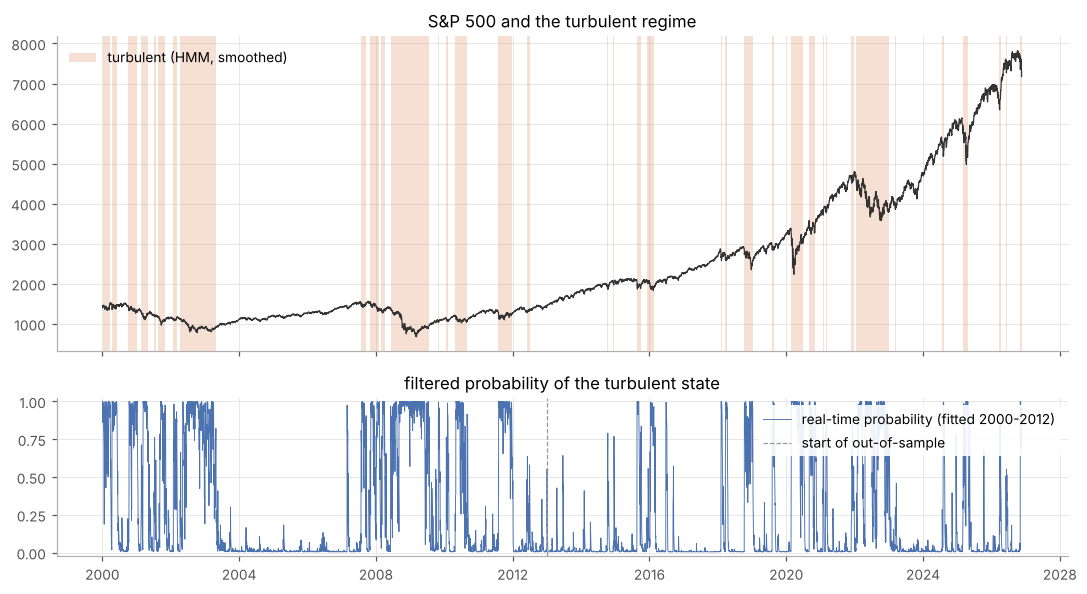

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(spx.index, spx.values, color="#333333", lw=0.8)
ax[0].fill_between(hmm.index, 0, 1, where=hmm.values, color="#dd8452", alpha=0.25, lw=0, transform=ax[0].get_xaxis_transform(), label="turbulent (HMM, smoothed)")
ax[0].set_title("S&P 500 and the turbulent regime"); ax[0].legend(loc="upper left")
ax[1].plot(f.index, f.values, lw=0.6, color="#4c72b0", label="real-time probability (fitted 2000-2012)")
ax[1].axvline(pd.Timestamp("2013-01-01"), color="#999999", lw=0.8, ls="--", label="start of out-of-sample")
ax[1].set_ylim(-0.02, 1.02); ax[1].set_title("filtered probability of the turbulent state")
ax[1].legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="none")
plt.tight_layout(); plt.savefig("regimes.png", dpi=130); plt.show()